# 03 · Treino: Random Forest com GridSearchCV

**Por que Random Forest:** a relação entre hora e lentidão não é linear (dois picos), há interações (pico × dia × ocorrência), o conjunto é pequeno e misto (contagens, horário, percentuais). A floresta lida com isso sem escalonar dados, é robusta a ruído e mostra a importância de cada variável, o que ajuda a explicar o resultado.

**O que o modelo prevê:** a *variação* da lentidão nos próximos 30 minutos. Numa primeira tentativa, prevendo direto o nível da lentidão, a floresta concentrou quase toda a importância em `lentidao_atual` e praticamente copiou o valor atual, sem ganho real sobre a linha de base. Prevendo a variação, ela precisa aprender **quando** o trânsito piora ou melhora (hora, dia, ocorrências). A previsão final é `lentidao_atual + variação prevista`.

**Busca:** 3 hiperparâmetros × 3 valores = **27 combinações**, com validação cruzada **só no treino**, agrupada por dia (cada dobra deixa um dia inteiro de fora).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

treino = pd.read_csv('dados/treino.csv', parse_dates=['timestamp'])
teste = pd.read_csv('dados/teste.csv', parse_dates=['timestamp'])
ALVO, ALVO_TREINO = 'lentidao_prox_30min', 'variacao_prox_30min'
FEATURES = [c for c in treino.columns if c not in ('timestamp', 'dia_semana', ALVO, ALVO_TREINO)]
X_tr, y_tr, d_tr = treino[FEATURES], treino[ALVO], treino[ALVO_TREINO]
X_te, y_te = teste[FEATURES], teste[ALVO]
grupos = treino['dia_semana']
print(X_tr.shape, X_te.shape)

(100, 23) (25, 23)


## Linha de base
Antes do modelo: e se disséssemos apenas que a lentidão daqui a 30 minutos será igual à de agora? O modelo só vale a pena se for melhor que isso.

In [2]:
def metricas(y, p):
    return {'MAE': mean_absolute_error(y, p), 'RMSE': np.sqrt(mean_squared_error(y, p)), 'R2': r2_score(y, p)}

base = pd.DataFrame({'treino': metricas(y_tr, X_tr['lentidao_atual']),
                     'teste': metricas(y_te, X_te['lentidao_atual'])}).T.round(3)
base

,MAE,RMSE,R2
treino,1.091,1.404,0.895
teste,1.188,1.598,0.789


## GridSearchCV

In [3]:
param_grid = {
    'n_estimators': [50, 100, 300],
    'max_depth': [3, 5, None],
    'min_samples_leaf': [1, 3, 5],
}
busca = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid,
    cv=GroupKFold(n_splits=4),
    scoring='neg_mean_absolute_error',
    return_train_score=True,
)
busca.fit(X_tr, d_tr, groups=grupos)  # treina na variação
print('Combinações testadas:', len(busca.cv_results_['params']))
print('Melhores parâmetros:', busca.best_params_)
print('MAE médio na validação cruzada: %.3f pontos de %%' % -busca.best_score_)

Combinações testadas: 27
Melhores parâmetros: {'max_depth': 3, 'min_samples_leaf': 3, 'n_estimators': 50}
MAE médio na validação cruzada: 0.849 pontos de %


In [4]:
res = pd.DataFrame(busca.cv_results_)
tabela = pd.DataFrame({
    'n_estimators': res['param_n_estimators'],
    'max_depth': res['param_max_depth'].map(lambda v: 'None' if v is None or v != v else int(v)).astype(str),
    'min_samples_leaf': res['param_min_samples_leaf'],
    'MAE_treino_cv': -res['mean_train_score'],
    'MAE_validacao_cv': -res['mean_test_score'],
    'desvio_validacao': res['std_test_score'],
    'rank': res['rank_test_score'],
}).sort_values('rank').round(3)
tabela.to_csv('resultados_grid.csv', index=False)
tabela

,n_estimators,max_depth,min_samples_leaf,MAE_treino_cv,MAE_validacao_cv,desvio_validacao,rank
3,50,3,3,0.661,0.849,0.074,1
0,50,3,1,0.637,0.851,0.083,2
12,50,5,3,0.565,0.856,0.073,3
4,100,3,3,0.660,0.860,0.064,4
5,300,3,3,0.660,0.861,0.051,5
9,50,5,1,0.482,0.863,0.086,6
21,50,None,3,0.534,0.868,0.074,7
13,100,5,3,0.563,0.868,0.068,8
1,100,3,1,0.632,0.868,0.078,9
2,300,3,1,0.634,0.868,0.075,10


## Treino × validação por combinação
Quanto maior a distância entre as duas curvas, mais o modelo decorou o treino (overfitting).

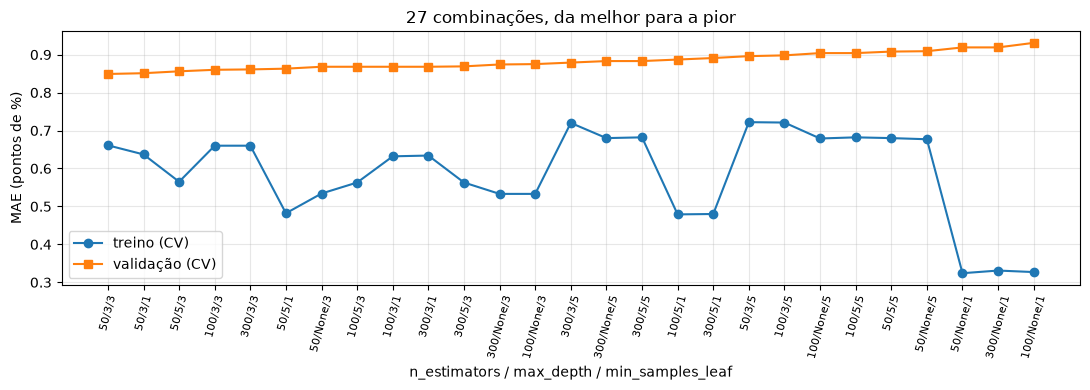

In [5]:
t = tabela.sort_values('MAE_validacao_cv').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t.index, t['MAE_treino_cv'], 'o-', label='treino (CV)')
ax.plot(t.index, t['MAE_validacao_cv'], 's-', label='validação (CV)')
ax.set_xticks(t.index, [f"{a}/{b}/{c}" for a, b, c in zip(t['n_estimators'], t['max_depth'], t['min_samples_leaf'])], rotation=75, fontsize=8)
ax.set(xlabel='n_estimators / max_depth / min_samples_leaf', ylabel='MAE (pontos de %)', title='27 combinações, da melhor para a pior')
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

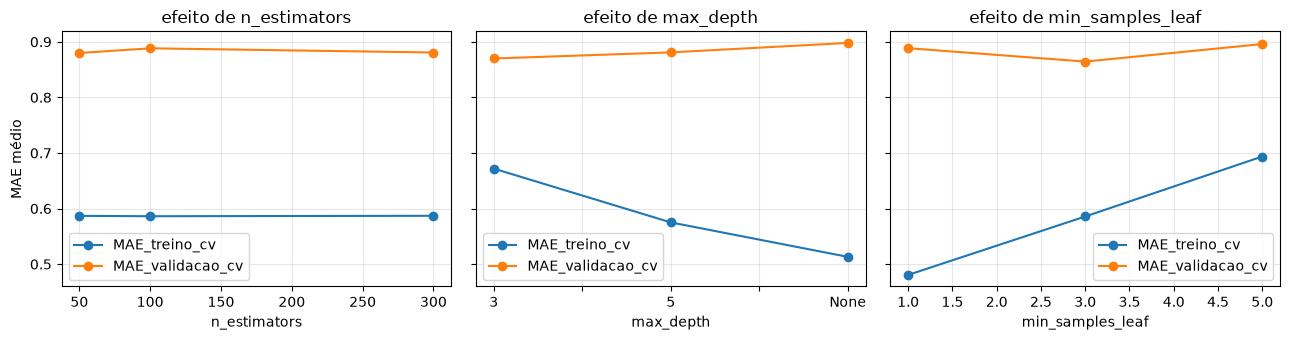

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, p in zip(axes, ['n_estimators', 'max_depth', 'min_samples_leaf']):
    g = tabela.groupby(p)[['MAE_treino_cv', 'MAE_validacao_cv']].mean()
    g.plot(ax=ax, marker='o', title=f'efeito de {p}')
    ax.grid(alpha=.3)
axes[0].set_ylabel('MAE médio'); plt.tight_layout(); plt.show()

## Resultado final: treino × teste lado a lado
O melhor modelo é retreinado em todo o treino (segunda a quinta) e avaliado uma única vez na sexta-feira.

In [7]:
modelo = busca.best_estimator_
# nível previsto = lentidão atual + variação prevista
p_tr = X_tr['lentidao_atual'] + modelo.predict(X_tr)
p_te = X_te['lentidao_atual'] + modelo.predict(X_te)
resultado = pd.DataFrame({
    'RF treino': metricas(y_tr, p_tr),
    'RF teste (sexta)': metricas(y_te, p_te),
    'Base teste (sexta)': metricas(y_te, X_te['lentidao_atual']),
}).T.round(3)
resultado

,MAE,RMSE,R2
RF treino,0.677,0.876,0.959
RF teste (sexta),0.902,1.096,0.901
Base teste (sexta),1.188,1.598,0.789


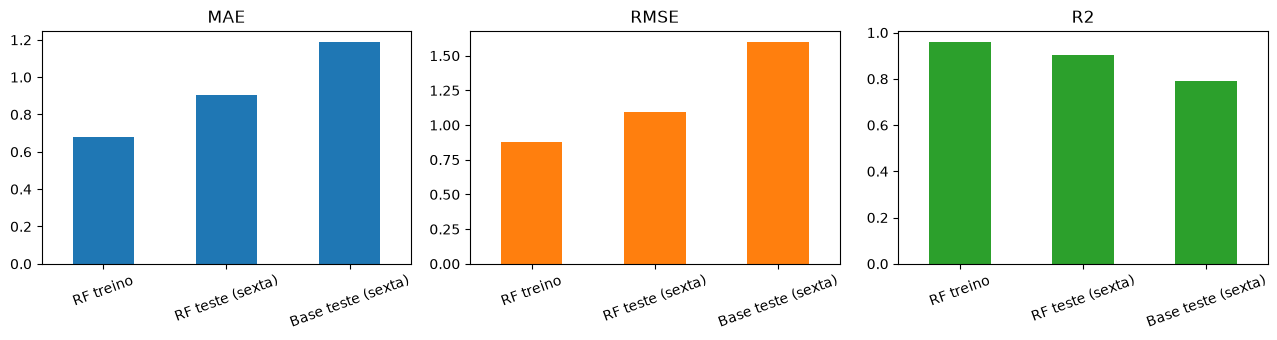

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
resultado[['MAE', 'RMSE', 'R2']].plot.bar(subplots=True, ax=ax, legend=False, rot=20)
plt.tight_layout(); plt.show()

## Previsão na sexta-feira (dia de teste)

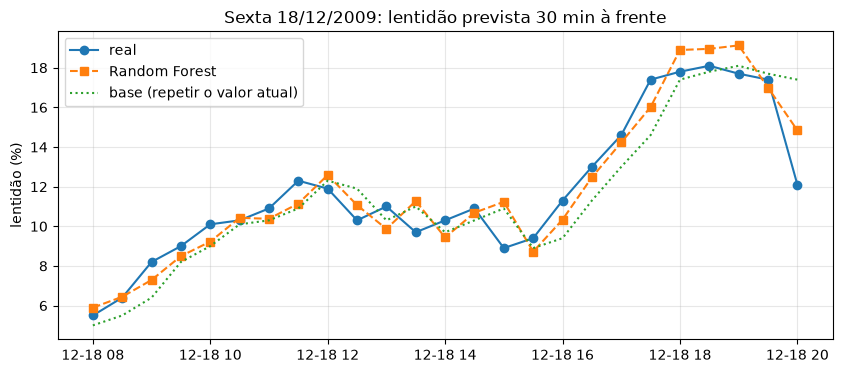

In [9]:
hora_alvo = teste['timestamp'] + pd.Timedelta(minutes=30)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hora_alvo, y_te, 'o-', label='real')
ax.plot(hora_alvo, p_te, 's--', label='Random Forest')
ax.plot(hora_alvo, X_te['lentidao_atual'], ':', label='base (repetir o valor atual)')
ax.set(ylabel='lentidão (%)', title='Sexta 18/12/2009: lentidão prevista 30 min à frente')
ax.legend(); ax.grid(alpha=.3); plt.show()

## Importância das variáveis

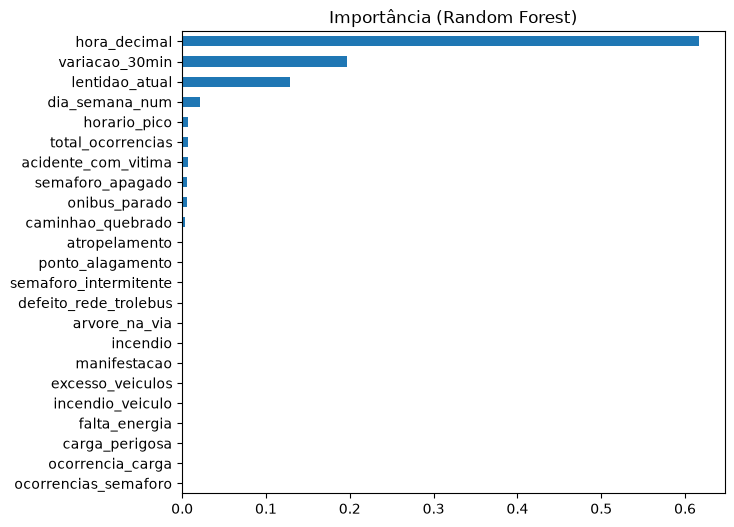

hora_decimal         0.616
variacao_30min       0.196
lentidao_atual       0.129
dia_semana_num       0.021
horario_pico         0.007
total_ocorrencias    0.007
dtype: float64

In [10]:
imp = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(7, 6), title='Importância (Random Forest)'); plt.show()
imp.sort_values(ascending=False).head(6).round(3)

In [11]:
joblib.dump(modelo, 'modelo_rf_lentidao.joblib')
print('Modelo salvo em modelo_rf_lentidao.joblib')

Modelo salvo em modelo_rf_lentidao.joblib


## Discussão: overfitting e o que o resultado significa

In [12]:
gap = resultado.loc['RF teste (sexta)', 'MAE'] - resultado.loc['RF treino', 'MAE']
ganho = 1 - resultado.loc['RF teste (sexta)', 'MAE'] / resultado.loc['Base teste (sexta)', 'MAE']
print(f"MAE treino: {resultado.loc['RF treino', 'MAE']:.2f} | MAE teste: {resultado.loc['RF teste (sexta)', 'MAE']:.2f} | diferença: {gap:.2f} p.p.")
print(f"Ganho sobre a linha de base no teste: {ganho:.0%}")

MAE treino: 0.68 | MAE teste: 0.90 | diferença: 0.22 p.p.
Ganho sobre a linha de base no teste: 24%


### Leitura dos resultados

| | MAE treino | MAE teste (sexta) | R² teste |
| --- | --- | --- | --- |
| Linha de base (repetir o valor atual) | – | 1,19 | 0,79 |
| Random Forest (melhor do grid) | 0,68 | **0,90** | **0,90** |

- **Melhor combinação:** `n_estimators=50`, `max_depth=3`, `min_samples_leaf=3`. As árvores rasas venceram: com `max_depth=None` o erro de treino cai, mas o de validação sobe. É o sinal clássico de overfitting num conjunto pequeno.
- **Overfitting controlado:** a diferença entre treino e teste é de cerca de 0,2 ponto percentual de lentidão. O modelo erra um pouco mais num dia que nunca viu, mas não desmorona.
- **Ganho real:** no dia de teste o erro médio cai cerca de 24% em relação a simplesmente repetir a lentidão atual.
- **O que o modelo aprendeu:** o horário é o fator principal (≈ 62% da importância), seguido da tendência dos últimos 30 minutos. Ou seja, ele sabe que no fim da tarde o trânsito tende a piorar, mesmo antes de piorar.
- **Limitação:** treinamos com 4 dias e testamos em 1 dia, todos de dezembro de 2009. Para generalizar (feriados, chuva, fins de semana) o próximo passo é a série histórica da CET de 2001 a 2019.

### O que isso significa para o cidadão

Com 30 minutos de antecedência e erro médio abaixo de 1 ponto percentual, a central consegue prever quando o trânsito vai piorar e esticar o verde das vias principais **antes** da fila se formar. Na prática, isso significa menos tempo parado para quem volta do trabalho no fim da tarde e um caminho mais livre para as ambulâncias justamente no horário em que a cidade mais trava.